# Dataset de Regressão
### "rent99": Dados de aluguéis de Munique de 1999
VISÃO GERAL: Dados sobre os aluguéis de imóveis em Munique e arquivos de delimitação territorial referentes à pesquisa realizada em 1999. Este conjunto de dados representa as informações sobre os aluguéis de Munique coletadas nessa pesquisa. Ele contém 3.082 observações e 9 variáveis:
- rent: valor líquido do aluguel mensal (em euros).
- rentsqm: valor líquido do aluguel mensal por metro quadrado (em euros).
- area: área habitável do imóvel, em metros quadrados.
- yearc: ano de construção do imóvel.
- location: qualidade da localização: variável categórica que indica se a localização é de qualidade média (1), boa (2) ou excelente (3).
- bath: qualidade do banheiro: variável categórica que indica se as instalações do banheiro são padrão (0) ou premium (1).
- kitchen: qualidade da cozinha: indica se a cozinha é padrão (0) ou premium (1).
- cheating: aquecimento central: variável categórica que indica a ausência (0) ou presença (1) de aquecimento central.


site:
https://rdrr.io/cran/gamlss.data/man/rent99.html

In [ ]:
# Connect Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Imports
import sys
from pathlib import Path

# Base project directory
BASE = Path('/content/drive/MyDrive/ML-Project')

# Add BASE directory to Python path
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))

# Import all functions from GraphicFunctions.py
from GraphicFunctions import *

print("GraphicFunctions carregado com sucesso!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GraphicFunctions carregado com sucesso!


In [ ]:
!pip install pyreadr

import requests
import tarfile
import io
import pyreadr
import pandas as pd
import numpy as np

url = "https://cran.r-project.org/src/contrib/gamlss.data_6.0-7.tar.gz"

response = requests.get(url)
response.raise_for_status()

arquivo = tarfile.open(
    fileobj=io.BytesIO(response.content),
    mode="r:gz"
)


rent_file = arquivo.extractfile(
    "gamlss.data/data/rent99.rda"
)


with open("/content/rent99.rda", "wb") as f:
    f.write(rent_file.read())


dados = pyreadr.read_r("/content/rent99.rda")

rent99 = list(dados.values())[0]


display(rent99.head(20))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 9.4 MB/s  0:00:00


,rent,rentsqm,area,yearc,location,bath,kitchen,cheating,district
0,109.948715,4.228797,26,1918.0,2,0,0,0,916
1,243.282043,8.688646,28,1918.0,2,0,0,1,813
2,261.641022,8.721369,30,1918.0,1,0,0,1,611
3,106.410255,3.547009,30,1918.0,2,0,0,0,2025
4,133.384613,4.446154,30,1918.0,2,0,0,1,561
5,339.025635,11.300851,30,1918.0,2,0,0,1,541
6,215.230774,6.942928,31,1918.0,1,0,0,0,822
7,323.230774,10.426800,31,1918.0,1,0,1,1,1713
8,216.307693,6.759615,32,1918.0,1,0,0,0,1812
9,245.282043,7.432790,33,1918.0,2,0,0,0,152


In [ ]:
import altair as alt

##Análise Exploratória

### Resumo estatístico

Inicialmente, vamos procurar mais informações relevantes a respeito dos dados, buscando os tipos de variáveis, valores ausentes e inconsistências.

In [ ]:
print(rent99.info())

print("Valores ausentes:")
print(rent99.isna().sum())

print("Linhas duplicadas:", rent99.duplicated().sum())
print()
print("Número de categorias:")
for col in ["location", "bath", "kitchen", "cheating"]:
    print(rent99[col].value_counts(dropna=False).sort_index())
    print()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3082 entries, 0 to 3081
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   rent      3082 non-null   float64 
 1   rentsqm   3082 non-null   float64 
 2   area      3082 non-null   int32   
 3   yearc     3082 non-null   float64 
 4   location  3082 non-null   category
 5   bath      3082 non-null   category
 6   kitchen   3082 non-null   category
 7   cheating  3082 non-null   category
 8   district  3082 non-null   int32   
dtypes: category(4), float64(3), int32(2)
memory usage: 109.0 KB
None
Valores ausentes:
rent        0
rentsqm     0
area        0
yearc       0
location    0
bath        0
kitchen     0
cheating    0
district    0
dtype: int64
Linhas duplicadas: 0

Número de categorias:
location
1    1794
2    1210
3      78
Name: count, dtype: int64

bath
0    2891
1     191
Name: count, dtype: int64

kitchen
0    2951
1     131
Name: count, dtype: int64

cheating
0

As variáveis não possuem duplicatas, valores ausentes ou inconsistências nas variáveis categóricas. Dado isso, podemos passar para o resumo estatístico.

Resumo estatístico: dimensões com .shape retornando a quantidade de observações (3082) e a quantidade de variáveis (9). Cria-se uma lista com as variáveis com print(rent99.columns.tolist()) e, para cada uma das variáveis numéricas (rent, rentsqm, area, yearc, distract), monta-se um resumo estatístico com display(rent99.describe()) com as seguintes informações:
- count: quantidade de observações NÃO ausentes.
- mean: média aritmética dos valores.
- std: desvio-padrão dos valores.
- min: menor valor de cada variável.
- 25%: primeiro quartil.
- 50%: mediana.
- 75%: terceiro quartil.
- max: maior valor de cada variável.

In [ ]:
print("Dimensões:", rent99.shape)
print("Variáveis:")
print(rent99.columns.tolist())

print("Resumo estatístico:")
display(rent99.describe())

Dimensões: (3082, 9)
Variáveis:
['rent', 'rentsqm', 'area', 'yearc', 'location', 'bath', 'kitchen', 'cheating', 'district']
Resumo estatístico:


,rent,rentsqm,area,yearc,district
count,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000
mean,459.437179,7.111259,67.374757,1956.306295,1169.715769
std,195.656638,2.436008,23.720446,22.308868,677.849333
min,40.512821,0.415800,20.000000,1918.000000,113.000000
25%,322.025635,5.260958,51.000000,1939.000000,561.000000
50%,426.974350,6.980241,65.000000,1959.000000,1025.000000
75%,559.358994,8.840824,81.000000,1972.000000,1714.000000
max,1843.384644,17.721611,160.000000,1997.000000,2529.000000


In [ ]:
display(rent99.describe())

,rent,rentsqm,area,yearc,district
count,3082.000000,3082.000000,3082.000000,3082.000000,3082.000000
mean,459.437179,7.111259,67.374757,1956.306295,1169.715769
std,195.656638,2.436008,23.720446,22.308868,677.849333
min,40.512821,0.415800,20.000000,1918.000000,113.000000
25%,322.025635,5.260958,51.000000,1939.000000,561.000000
50%,426.974350,6.980241,65.000000,1959.000000,1025.000000
75%,559.358994,8.840824,81.000000,1972.000000,1714.000000
max,1843.384644,17.721611,160.000000,1997.000000,2529.000000


O resumo estatístico mostra que:
1. Assimetria nos aluguéis: o aluguel médio é de aproximadamente €459, enquanto a mediana é €427. Como a média supera a mediana e o valor máximo (€1.843) é muito superior ao terceiro quartil (€559), há indícios de uma cauda à direita, formada por uma parcela pequena de imóveis com aluguéis elevados.
2. Variação dos aluguéis: o desvio-padrão de rent é de aproximadamente €196, equivalente a cerca de 42,6% da média. Portanto, os valores de aluguel apresentam heterogeneidade relevante na amostra.
3. Diferenças de tamanho: a área mediana é de 65 m², com 50% dos imóveis entre 51 e 81 m². O intervalo total vai de 20 a 160 m². É relevante investigar se imóveis maiores apresentam aluguéis totais maiores e se o aluguel por metro quadrado também varia com a área.
4. Diversidade de idade dos imóveis: os anos de construção vão de 1918 a 1997, e a mediana é 1959. A distribuição temporal não é uniforme; por isso, será importante observar em quais períodos há maior concentração de imóveis antes de interpretar a relação entre idade e aluguel.

### Plotagens dos dados

#### Distribuição de aluguéis

In [ ]:
hist_rent = alt.Chart(rent99).mark_bar(
    color="#E879B9",
    opacity=0.85
).encode(
    x=alt.X(
        "rent:Q",
        bin=alt.Bin(maxbins=35),
        title="Alugue líquido (€)"
    ),
    y=alt.Y(
        "count():Q",
        title="Número de imóveis"
    ),
    tooltip=["count():Q"]
).properties(
    title="Distribuição dos aluguéis mensais",
    width=650,
    height=350
)

hist_rent

alt.Chart(...)

A distribuição é assimétrica à direita: a maior concentração de imóveis está nas faixas intermediárias, aproximadamente entre €300 e €600, enquanto a frequência diminui progressivamente à medida que os aluguéis aumentam. O intervalo de aproximadamente €350 a €400 é o mais frequente no histograma.

Essa cauda à direita é coerente com a diferença entre a média (€459) e a mediana (€427). Embora a maior parte dos imóveis esteja concentrada em valores bem inferiores ao máximo, existem observações com aluguéis muito elevados: cerca de 2,9% da amostra apresenta aluguel superior a €900, e aproximadamente 1,7% supera €1.000.

Como a distribuição de rent não é simétrica e contém valores altos relativamente raros, alguns modelos de regressão podem ser sensíveis a esse tipo de observações extremas, especialmente quando utilizam erros quadráticos.

#### Dispersão rent: area, location, yearc e district

In [ ]:
import altair as alt

# Gráfico 1: Rent x Area
grafico_area = alt.Chart(rent99).mark_circle(
    size=35, opacity=0.4
).encode(
    x=alt.X("area:Q", title="Área (m²)"),
    y=alt.Y("rent:Q", title="Aluguel mensal (€)"),
    tooltip=["area", "rent"]
).properties(
    title="Aluguel x Área",
    width=750,
    height=300
)

# Gráfico 2: Rent x Location
grafico_location = alt.Chart(rent99).mark_boxplot().encode(
    x=alt.X("location:O", title="Qualidade da localização"),
    y=alt.Y("rent:Q", title="Aluguel mensal (€)"),
    color=alt.Color("location:N", title="Localização")
).properties(
    title="Aluguel x Localização",
    width=750,
    height=300
)

# Gráfico 3: Rent x Yearc
grafico_yearc = alt.Chart(rent99).mark_circle(
    size=35, opacity=0.4
).encode(
    x=alt.X("yearc:Q", title="Ano de construção", scale=alt.Scale(domain=[1915, 2000])),
    y=alt.Y("rent:Q", title="Aluguel mensal (€)"),
    tooltip=["yearc", "rent"]
).properties(
    title="Aluguel x Ano de construção",
    width=750,
    height=300
)

# Gráfico 4: Rent x District
grafico_district = alt.Chart(rent99).mark_circle(
    size=35, opacity=0.35
).encode(
    x=alt.X("district:O", title="Distrito", axis=alt.Axis(labelAngle=-45)),
    y=alt.Y("rent:Q", title="Aluguel mensal (€)"),
    tooltip=["district", "rent"]
).properties(
    title="Aluguel x Distrito",
    width=750,
    height=300
)

# Organização vertical
graficos = alt.vconcat(
    grafico_area,
    grafico_location,
    grafico_yearc,
    grafico_district,
    spacing=25
).resolve_scale(
    y="shared"
).properties(
    title="Análise exploratória das variáveis relacionadas ao aluguel"
)

graficos

alt.VConcatChart(...)

1. Aluguel mensal × Área

O gráfico apresenta uma associação positiva com imóveis com maior área possuindo aluguéis mensais mais elevados. A correlação de Pearson entre as duas variáveis é aproximadamente 0,585, indicando uma associação linear positiva moderada, não uma relação perfeita.

A dispersão vertical também aumenta entre os imóveis maiores. Por exemplo, para áreas próximas de 70–90 m² há uma faixa ampla de valores de aluguel, e, acima de 100 m², aparecem tanto aluguéis moderados quanto valores bastante elevados. Isso indica que a área ajuda a explicar a variação do aluguel, mas não é suficiente para explicá-la sozinha.

A mediana do aluguel também cresce por faixas de área con aproximadamente €296 para imóveis de até 40 m², €381 entre 40 e 60 m², €469 entre 60 e 80 m² e €533 entre 80 e 100 m².

2. Aluguel mensal × Qualidade da localização

As medianas dos três grupos aumentam conforme a classificação da localização: aproximadamente €415 para localização média (categoria 1), €443 para boa (categoria 2) e €646 para excelente (categoria 3). A diferença entre as categorias 1 e 2 é relativamente pequena, enquanto a categoria 3 apresenta uma mediana consideravelmente maior.

A categoria excelente, entretanto, contém apenas 78 imóveis (cerca de 2,5% da amostra), contra 1.794 na categoria média e 1.210 na categoria boa. Portanto, a diferença observada na categoria 3 é relevante, mas deve ser interpretada com cautela devido ao tamanho menor desse grupo.

3. Aluguel mensal × Ano de construção

O gráfico não mostra uma relação linear forte entre ano de construção e aluguel. A correlação de Pearson é de aproximadamente 0,134, valor que indica uma associação linear positiva fraca.

Visualmente, há grande dispersão dos aluguéis em praticamente todos os períodos. Também se observa concentração de imóveis construídos em 1918 e entre as décadas de 1950 e 1970, enquanto há poucos registros entre 1941 e 1950.

Apesar da correlação fraca, os imóveis mais recentes apresentam aluguéis medianos mais elevados: a mediana passa de aproximadamente €417 entre 1960 e 1970 para €441 entre 1970 e 1980, €541 entre 1980 e 1990 e €584 entre 1990 e 1997. Isso sugere que a relação pode não ser bem descrita por uma única tendência linear.

4. Aluguel mensal × Distrito

O gráfico forma faixas verticais porque cada distrito é representado por um código categórico e reúne os imóveis.

A principal informação do gráfico é que os aluguéis variam bastante entre imóveis do mesmo distrito e também entre distritos. Como a visualização contém muitas categorias sobrepostas, a comparação de medianas por distrito é mais adequada para investigar diferenças regionais. Essa comparação deve considerar o número de imóveis de cada distrito.

#### Curva de tendência

In [ ]:
def grafico_tendencia(coluna, titulo, dominio_x=None):

    escala = alt.Scale(domain=dominio_x) if dominio_x is not None else alt.Scale()

    pontos = alt.Chart(rent99).mark_circle(
        size=30,
        opacity=0.25
    ).encode(
        x=alt.X(f"{coluna}:Q", title=titulo, scale=escala),
        y=alt.Y("rent:Q", title="Aluguel mensal (€)")
    )

    tendencia = alt.Chart(rent99).transform_loess(
        coluna,
        "rent",
        bandwidth=0.5
    ).mark_line(size=3).encode(
        x=alt.X(f"{coluna}:Q", title=titulo, scale=escala),
        y=alt.Y("rent:Q")
    )

    return (pontos + tendencia).properties(
        width=750,
        height=300,
        title=f"Tendência: aluguel x {titulo}"
    )


grafico_area_tendencia = grafico_tendencia(
    "area", "Área (m²)"
)

grafico_yearc_tendencia = grafico_tendencia(
    "yearc", "Ano de construção", dominio_x=[1915, 2000]
)

alt.vconcat(
    grafico_area_tendencia,
    grafico_yearc_tendencia
)

alt.VConcatChart(...)

Análise das curvas de tendência
1. Área do imóvel

A curva LOESS apresenta uma tendência crescente ao longo de praticamente toda a faixa de área: conforme o tamanho do imóvel aumenta, o aluguel mensal esperado também aumenta. A inclinação é mais evidente nas faixas em que há maior concentração de observações, aproximadamente entre 40 e 100 m².

Nas áreas maiores, a curva continua subindo, mas há menos pontos e a dispersão dos aluguéis é maior.

2. Ano de construção

A curva apresenta um comportamento diferente, ficando estável ou com pequenas oscilações nos períodos mais antigos e passando a subir de forma mais perceptível a partir das décadas de 1970 e 1980. Isso sugere que a relação entre ano de construção e aluguel pode ser não linear.

A curva LOESS é uma suavização dos dados, não uma estimativa causal. Ela mostra o padrão médio local observado na amostra, mas não controla simultaneamente por área, localização ou características internas do imóvel.

### Distribuição das características dos imóveis

Além de analisar a distribuição dos valores de aluguel, é importante compreender como as características físicas dos imóveis estão distribuídas na amostra.

Os histogramas de área e ano de construção permitem identificar as faixas mais frequentes, possíveis concentrações e assimetrias. Essas informações ajudam a compreender melhor a composição do conjunto de dados antes da aplicação dos modelos de regressão.

In [ ]:
hist_area = alt.Chart(rent99).mark_bar(
    opacity=0.8
).encode(
    x=alt.X("area:Q", bin=alt.Bin(maxbins=30), title="Área (m²)"),
    y=alt.Y("count():Q", title="Número de imóveis"),
    tooltip=["count():Q"]
).properties(
    title="Distribuição da área dos imóveis",
    width=650,
    height=300
)

hist_yearc = alt.Chart(rent99).mark_bar(
    opacity=0.8
).encode(
    x=alt.X("yearc:Q", bin=alt.Bin(maxbins=30), title="Ano de construção"),
    y=alt.Y("count():Q", title="Número de imóveis"),
    tooltip=["count():Q"]
).properties(
    title="Distribuição dos anos de construção",
    width=650,
    height=300
)

alt.vconcat(hist_area, hist_yearc)

alt.VConcatChart(...)

**Distribuição da área**

A área dos imóveis está concentrada principalmente entre 50 e 80 m². Essa faixa reúne aproximadamente metade das observações (1.548 de 3.082). A mediana é 65 m², e 50% dos imóveis possuem área entre 51 e 81 m². A frequência diminui nas áreas maiores com apenas cerca de 8,3% dos imóveis possuem mais de 100 m². Há, portanto, uma cauda à direita, com poucos imóveis de grande dimensão, chegando ao máximo de 160 m².

**Distribuição do ano de construção**

A distribuição temporal apresenta concentrações importantes em dois períodos, primeiro em 1918–1930, com 670 imóveis, e 1950–1960, com 766 imóveis.

Em contraste, o intervalo de 1941 a 1950 possui apenas 22 imóveis, ou s4eja, isso impacta a curva de tendência, já que as comparações entre períodos não têm a mesma quantidade de informação ao longo de todo o eixo temporal.

### Relação entre o aluguel e as características dos imóveis

Além da área, da localização e do ano de construção, o conjunto de dados apresenta características relacionadas às instalações dos imóveis.

As variáveis `bath`, `kitchen` e `cheating` representam, respectivamente, a categoria do banheiro, da cozinha e a presença de aquecimento central.

A comparação dos valores de aluguel entre essas categorias permite investigar se existem diferenças nas distribuições dos preços associadas a essas características.

In [ ]:
def grafico_categorico(coluna, titulo):
    return alt.Chart(rent99).mark_boxplot().encode(
        x=alt.X(f"{coluna}:N", title=titulo),
        y=alt.Y("rent:Q", title="Aluguel mensal (€)"),
        color=alt.Color(f"{coluna}:N", legend=None),
        tooltip=[coluna, "rent"]
    ).properties(
        title=f"Aluguel mensal × {titulo}",
        width=600,
        height=300
    )

alt.vconcat(
    grafico_categorico("bath", "Categoria do banheiro"),
    grafico_categorico("kitchen", "Categoria da cozinha"),
    grafico_categorico("cheating", "Aquecimento central")
)

alt.VConcatChart(...)

1. Categoria do banheiro (bath)

A mediana do aluguel é de aproximadamente €418 para banheiros padrão (categoria 0) e €587 para banheiros premium (categoria 1). A diferença é expressiva, mas a categoria premium reúne somente 191 imóveis (6,2% da amostra), enquanto 2.891 possuem banheiro padrão.

O boxplot também mostra maior dispersão no grupo premium. A diferença entre as medianas sugere associação entre a categoria do banheiro e o aluguel, mas não permite concluir que o banheiro, isoladamente, cause o aumento: imóveis com banheiro premium também podem diferir em área, localização e outras características.

2. Categoria da cozinha (kitchen)

A mediana é de aproximadamente €421 para cozinhas padrão e €616 para cozinhas premium. Entretanto, apenas 131 imóveis (4,3% da amostra) estão na categoria premium, contra 2.951 na categoria padrão.

A diferença observada é relevante, mas o grupo premium é pequeno. Além disso, há sobreposição entre as distribuições e valores extremos em ambos os grupos. A variável pode ser informativa para a regressão, mas sua contribuição deve ser avaliada em conjunto com as demais características.

3. Presença de aquecimento central (cheating)

Os imóveis com aquecimento central (categoria 1) apresentam mediana de aluguel de aproximadamente €443, enquanto aqueles sem aquecimento central (categoria 0) apresentam mediana de €302, com uma diferença considerável.

Assim como nos demais, a distribuição é desequilibrada, com 2.761 imóveis possuindo aquecimento central e 321 não possuindo.

Nos três gráficos, as diferenças entre medianas indicam associações úteis para investigar na modelagem. Contudo, não devem ser interpretadas como efeitos isolados ou causais, pois as características dos imóveis podem ocorrer conjuntamente.

### Relação entre o preço por metro quadrado e a área dos imóveis

O valor de aluguel por metro quadrado permite analisar a relação entre o tamanho dos imóveis e seu custo relativo.

Essa análise é complementar à comparação entre aluguel mensal e área, pois imóveis maiores podem apresentar aluguéis totais mais elevados, mas isso não significa necessariamente que também possuam um preço por metro quadrado maior.

A investigação dessa relação pode ajudar a compreender melhor o comportamento dos preços e as diferenças entre imóveis de tamanhos distintos.

In [ ]:
grafico_rentsqm = alt.Chart(rent99).mark_circle(
    size=35,
    opacity=0.35
).encode(
    x=alt.X("area:Q", title="Área (m²)"),
    y=alt.Y("rentsqm:Q", title="Aluguel por m² (€)"),
    tooltip=["area", "rentsqm"]
)

tendencia_rentsqm = alt.Chart(rent99).transform_loess(
    "area",
    "rentsqm",
    bandwidth=0.5
).mark_line(size=3).encode(
    x=alt.X("area:Q", title="Área (m²)"),
    y=alt.Y("rentsqm:Q", title="Aluguel por m² (€)")
)

(grafico_rentsqm + tendencia_rentsqm).properties(
    title="Aluguel por metro quadrado × Área",
    width=750,
    height=350
)

alt.LayerChart(...)

Os valores medianos por faixas de área ilustram esse padrão: aproximadamente €9,13/m² para imóveis de até 40 m², €7,28/m² entre 40 e 60 m², €6,70/m² entre 60 e 80 m² e €6,00/m² entre 80 e 100 m². Nas faixas maiores, a mediana fica próxima de €5,4–€5,5/m².

Essa variável é útil para o custo relativo dos imóveis, não devendo ser utilizada como preditora quando o objetivo é prever rent, pois contém diretamente o valor-alvo em sua fórmula.

### Comparação dos valores de aluguel entre os distritos

In [ ]:
mediana_distritos = (
    rent99.groupby("district")["rent"]
    .median()
    .sort_values()
)

distritos_extremos = pd.concat([
    mediana_distritos.head(15),
    mediana_distritos.tail(15)
]).reset_index()

grafico_distritos = alt.Chart(distritos_extremos).mark_bar().encode(
    x=alt.X("rent:Q", title="Mediana do aluguel mensal (€)"),
    y=alt.Y("district:N", sort="-x", title="Distrito"),
    tooltip=["district", "rent"]
).properties(
    title="15 distritos com menores e maiores medianas de aluguel",
    width=750,
    height=600
)

grafico_distritos

alt.Chart(...)

A comparação original das medianas mostra diferenças expressivas entre distritos, mas também revela que muitos distritos possuem pouquíssimas observações. No conjunto completo, há 336 distritos; a mediana do número de imóveis por distrito é apenas 6, e 46 distritos possuem uma única observação.

Quando um distrito tem apenas um imóvel, sua mediana é simplesmente o aluguel daquele único registro. Assim, os extremos encontrados sem considerar o tamanho dos grupos podem refletir casos isolados, e não um padrão regional consistente.

Para tornar a comparação mais informativa, o gráfico foi ajustado para incluir somente distritos com pelo menos 10 imóveis. Mesmo com esse filtro, a mediana dos aluguéis varia: entre os 15 distritos com menores medianas, os valores começam em aproximadamente €260; entre os 15 com maiores medianas, chegam a aproximadamente €793. O filtro reduz o risco de destacar distritos com amostras extremamente pequenas, mas não elimina toda a incerteza: os grupos ainda possuem tamanhos diferentes. Portanto, a comparação deve ser vista como exploratória, não como um ranking definitivo de custo de moradia.

#### Matriz de correlação das variáveis numéricas

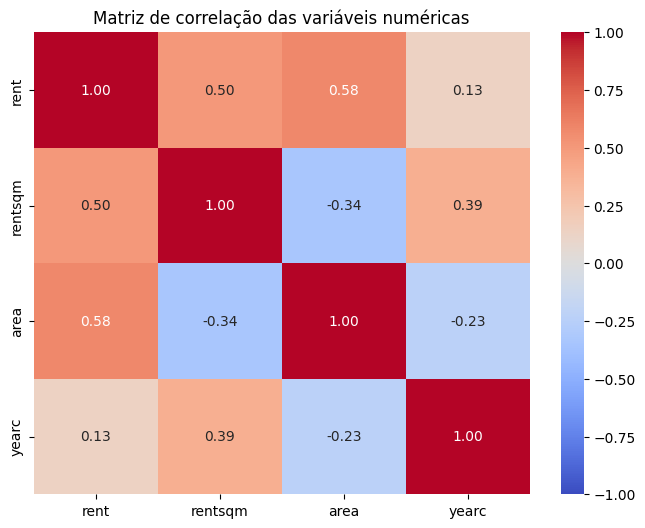

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

variaveis_numericas = [
    "rent",
    "rentsqm",
    "area",
    "yearc"
]

matriz_corr = rent99[variaveis_numericas].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlação das variáveis numéricas")
plt.show()

A matriz mostra associações lineares de intensidades diferentes:
- rent e area: correlação positiva moderada (0,58). Imóveis maiores tendem a apresentar aluguéis totais maiores.
- rent e rentsqm: correlação positiva moderada (0,50). Aluguéis totais maiores tendem também a estar associados a valores maiores por metro quadrado, embora essa relação seja influenciada pela área.
- rent e yearc: correlação positiva fraca (0,13). Isso confirma que o ano de construção, isoladamente, possui uma associação linear pequena com o aluguel, apesar do aumento observado em períodos mais recentes na curva LOESS.
- rentsqm e area: correlação negativa moderada (−0,34). Em geral, imóveis maiores apresentam menor aluguel por metro quadrado.
- rentsqm e yearc: correlação positiva moderada (0,39). Imóveis mais recentes tendem, nesta amostra, a apresentar maior aluguel por metro quadrado.
- area e yearc: correlação negativa fraca (−0,23). Há uma tendência leve de imóveis mais recentes apresentarem áreas menores.
É importante destacar que rentsqm é calculada a partir de rent / area. Portanto, as correlações envolvendo essa variável possuem uma dependência matemática e não devem ser interpretadas como relações independentes.

A matriz considera apenas associações lineares entre variáveis numéricas. Ela não captura necessariamente relações não lineares, não demonstra causalidade e não substitui a avaliação dos modelos. Além disso, location, bath, kitchen e cheating são variáveis categóricas e não aparecem nesta matriz.

### Aprendizado não supervisionado



#### PCA

Para aplicar o PCA à esse dataset, restringimos nosso foco para as features area, yearc, location, bath, kitchen e cheating. Excluímos rentsqm pois ela se deriva da variável alvo, e district pois não tem significado númerico e nem mesmo ordinal. As variáveis restantes foram normalizadas previamente com média 0 e desvio padrão 1.

In [ ]:
FEATURES_REG = ["area", "yearc", "location", "bath", "kitchen", "cheating"]

X_reg = rent99[FEATURES_REG].to_numpy(dtype=float)
Z_reg = normalize(X_reg)
pca_reg, S_reg, tab_pca_reg, var_exp_reg, var_acum_reg = fit_pca(Z_reg, FEATURES_REG)
display(tab_pca_reg)

,PC1,PC2,PC3,PC4,PC5
area,-0.381497,0.556645,-0.105110,-0.205651,-0.544326
yearc,0.648339,0.107959,-0.050986,0.160493,0.182459
location,-0.347496,0.157077,0.040979,0.915753,0.101510
bath,-0.002749,0.680744,-0.276291,-0.156760,0.613846
kitchen,0.162482,0.345669,0.915307,-0.027307,-0.025870
cheating,0.535682,0.266303,-0.265611,0.260821,-0.531636


In [ ]:
# Gráfico do cotovelo do PCA
display(pca_elbow_chart(var_exp_reg, var_acum_reg))

alt.LayerChart(...)

Para explicar 90% da variância, são necessárias 5 de 6 componentes. Isso indica uma baixa redundância entre as features, sendo um caso onde o PCA não é tão vantajoso.

Analisando as cargas, temos algumas observações sobre as primeiras 4 componentes:

-   **PC1 (25.8%):** Favorece yearc e cheating contra area e location. Uma possível interpretação é que imóveis mais antigos são maiores e tem localizações melhores, enquanto os mais novos são menores, possuem localizações piores e aquecimento central
-   **PC2 (21.2%):** Favorece area, bath e kitchen ao mesmo tempo.
-   **PC3 e PC4:** Concentram a carga em uma só feature (kitchen e location), indicando que essas são features mais isoladas.


#### K-means

In [ ]:
models_reg, wss_reg, tab_wss_reg = sweep_k(S_reg)
display(tab_wss_reg)

,K,WSS,Queda absoluta,Queda %
0,2,13423.53,0.00,0.00
1,3,10403.66,3019.87,22.50
2,4,7870.06,2533.60,24.35
3,5,5171.58,2698.48,34.29
4,6,4141.44,1030.14,19.92
5,7,3526.55,614.89,14.85
6,8,3252.35,274.20,7.78
7,9,2970.15,282.20,8.68
8,10,2772.05,198.10,6.67


In [ ]:
# Gráfico do cotovelo K-means
display(wss_chart(wss_reg))

alt.Chart(...)

Para aplicar o KMeans, construímos o gráfico da WSS e argumentamos que é possível visualizar um cotovelo em K=5, justificando a nossa escolha de hiperparâmetro.

In [ ]:
# Gráfico PCA + centroides
K_REG = 5
km_reg = KMeans(k=K_REG, seed=SEED).fit(S_reg)

names_cl_reg = [f"C{i}" for i in range(K_REG)]
color_reg = ("cluster", [f"C{c}" for c in km_reg.labels],
           alt.Color("cluster:N", title="Cluster",
                     scale=alt.Scale(domain=names_cl_reg, range=CLUSTER_COLORS[:K_REG])))
display(projection_chart(S_reg, km_reg, color_reg))

alt.LayerChart(...)

Os clusters não são bem separados, pelo menos não de forma nítida quando se análisa a dispersão nas primeiras 2 componentes. O aprendizado não supervisionado possuí baixa efetividade nesse dataset, em parte porque as features tem baixa correlação. Vale notar também que 4 das features que usamos são categóricas, prejudicando o PCA e o KMeans que costumam lidar com features numéricas.

##Primeira Etapa do Pré-Processamento

O objetivo do projeto é prever o valor líquido do aluguel mensal (rent). Por isso, a variável rentsqm será removida antes da preparação dos dados para a modelagem.

Essa variável representa o aluguel mensal dividido pela área do imóvel (rent / area). Como o próprio valor que desejamos prever aparece em sua fórmula, utilizá-la como variável explicativa causaria vazamento de informação (data leakage): o modelo teria acesso indireto ao valor-alvo durante o treinamento.

A área (area), por outro lado, pode ser mantida como preditora, pois é uma característica do imóvel que não é calculada a partir do aluguel.

A remoção é feita nesta etapa para gerar uma base inicial sem essa variável derivada. As demais etapas de pré-processamento — como codificação das variáveis categóricas, divisão entre treino e teste e eventual padronização — deverão ser definidas de acordo com cada modelo.


In [ ]:
rent99 = rent99.drop('rentsqm', axis=1)

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

caminho_arquivo = '/content/drive/MyDrive/ML-Project/dataset_limpo.csv'


rent99.to_csv(caminho_arquivo, index=False)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
